
# Bank Marketing Campaign Analysis

**Exploratory Data Analysis Using Python**

## Project Objective

This project analyzes a Portuguese bank's marketing campaign data to explore customer subscription behavior and identify opportunities to improve campaign targeting.

## Dataset

- Source: UCI Machine Learning Repository
- Dataset: Bank Marketing
- Records: 45,211
- Original columns: 17
- Tools: Python, Pandas, Matplotlib, Seaborn

## Research Questions

1. What is the overall subscription rate?
2. Which age and job groups have higher conversion rates?
3. How is the number of contacts related to subscription rates?
4. How does previous campaign outcome relate to subscription behavior?

In [31]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import urllib.request

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

urllib.request.urlretrieve(url, "bank_marketing.zip")

with zipfile.ZipFile("bank_marketing.zip", "r") as z:
    with z.open("bank.zip") as inner_zip_file:
        with zipfile.ZipFile(inner_zip_file) as inner_zip:
            with inner_zip.open("bank-full.csv") as csv_file:
                df = pd.read_csv(csv_file, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Bank Marketing Campaign Analysis

Exploratory Data Analysis Using Python

Project Objective

This project analyzes a Portuguese bank's marketing campaign data to explore customer subscription behavior and identify potential opportunities to improve campaign targeting.

Dataset

Source: UCI Machine Learning Repository — Bank Marketing

Records: 45,211

Original features: 17

Tools: Python, Pandas, Matplotlib, Seaborn

Research Questions

What is the overall subscription rate?

Which customer age and job groups have higher conversion rates?

How is the number of campaign contacts associated with subscription rates?

How does previous campaign outcome relate to current subscription behavior?

In [32]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [33]:

df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [34]:

df["y"].value_counts()

df["y"].value_counts(normalize=True) * 100


,proportion
y,
no,88.30152
yes,11.69848


In [35]:

job_analysis = df.groupby("job")["y"].apply(
    lambda x: (x == "yes").mean() * 100
)

job_analysis = job_analysis.sort_values(ascending=False)

print(job_analysis.round(2))

job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: y, dtype: float64


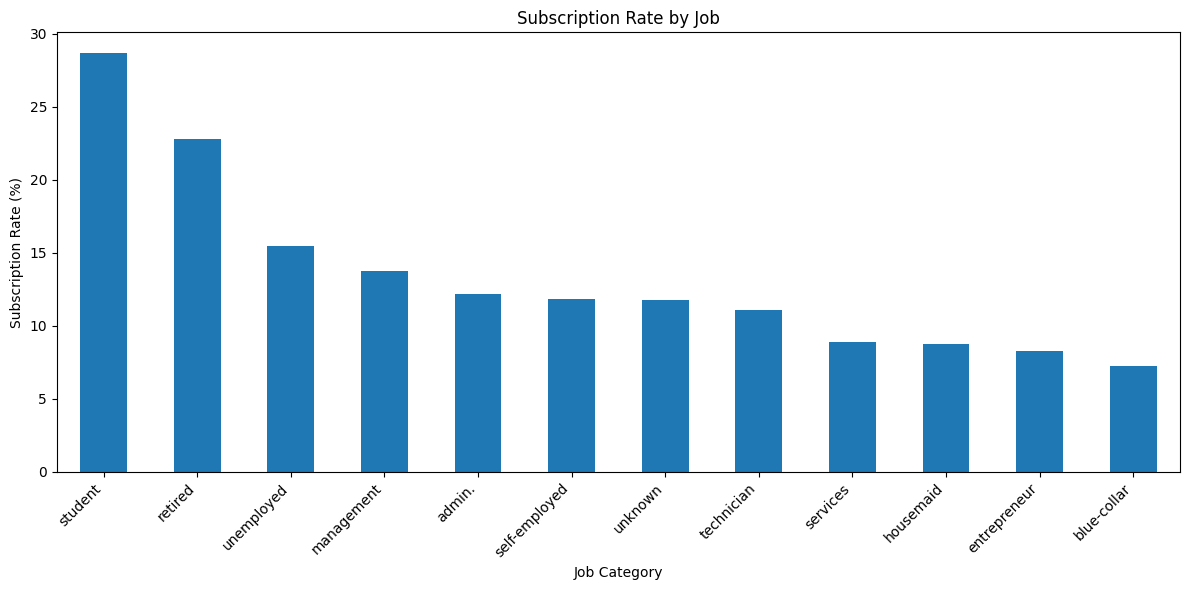

In [36]:
import matplotlib.pyplot as plt

job_analysis.plot(kind="bar", figsize=(12, 6))

plt.title("Subscription Rate by Job")
plt.xlabel("Job Category")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [37]:
job_summary = df.groupby("job")["y"].agg(
    total_customers="count",
    subscriptions=lambda x: (x == "yes").sum()
)

job_summary["conversion_rate"] = (
    job_summary["subscriptions"] /
    job_summary["total_customers"] * 100
)

job_summary = job_summary.sort_values(
    by="conversion_rate",
    ascending=False
)

job_summary.round(2)

,total_customers,subscriptions,conversion_rate
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


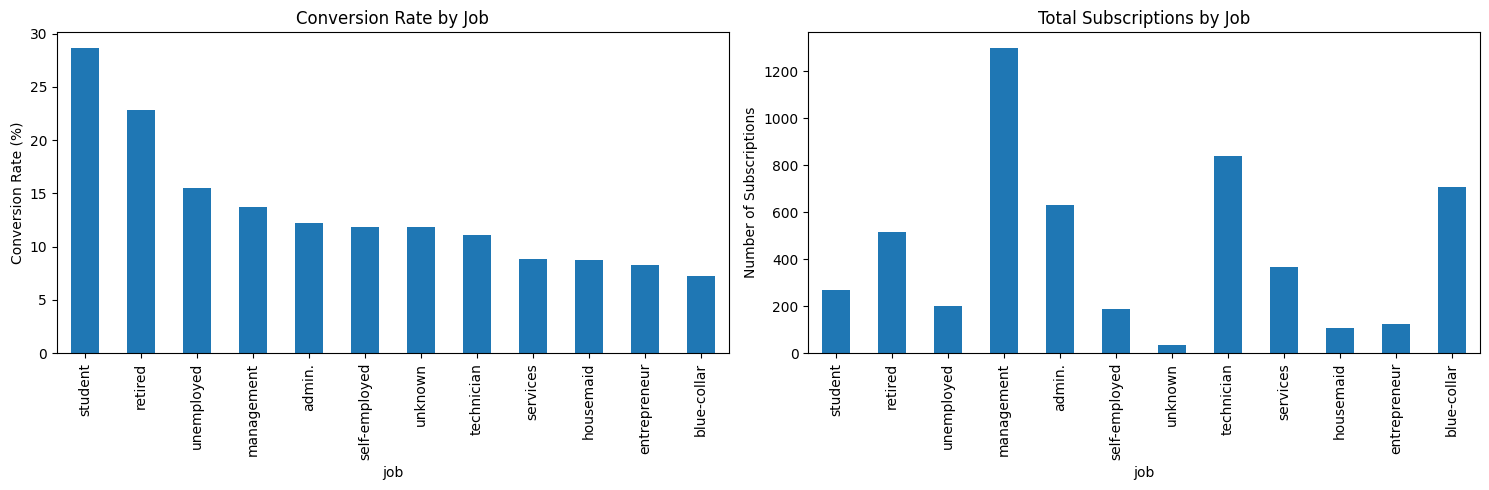

In [38]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

job_summary["conversion_rate"].plot(
    kind="bar",
    ax=axes[0],
    title="Conversion Rate by Job"
)

job_summary["subscriptions"].plot(
    kind="bar",
    ax=axes[1],
    title="Total Subscriptions by Job"
)

axes[0].set_ylabel("Conversion Rate (%)")
axes[1].set_ylabel("Number of Subscriptions")

plt.tight_layout()
plt.show()


In [39]:

df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [40]:

(df == "unknown").sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day,0


In [41]:

df.duplicated().sum()

np.int64(0)

In [42]:

unknown_percent = (df == "unknown").sum() / len(df) * 100

print(unknown_percent[unknown_percent > 0].round(2))

job           0.64
education     4.11
contact      28.80
poutcome     81.75
dtype: float64


In [43]:

print("Average Age:", df["age"].mean())
print("Minimum Age:", df["age"].min())
print("Maximum Age:", df["age"].max())
print("Median Age:", df["age"].median())

Average Age: 40.93621021432837
Minimum Age: 18
Maximum Age: 95
Median Age: 39.0


In [44]:

age_bins = [18, 25, 35, 45, 55, 65, 100]

age_labels = [
    "18-24", "25-34", "35-44",
    "45-54", "55-64", "65+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

df[["age", "age_group"]].head()

,age,age_group
0,58,55-64
1,44,35-44
2,33,25-34
3,47,45-54
4,33,25-34


In [45]:
age_summary = df.groupby(
    "age_group", observed=True
)["y"].agg(
    total_customers="count",
    subscriptions=lambda x: (x == "yes").sum()
)

age_summary["conversion_rate"] = (
    age_summary["subscriptions"] /
    age_summary["total_customers"] * 100
)

age_summary.round(2)

,total_customers,subscriptions,conversion_rate
age_group,,,
18-24,809,207,25.59
25-34,14204,1773,12.48
35-44,14534,1404,9.66
45-54,9958,923,9.27
55-64,4896,641,13.09
65+,810,341,42.10


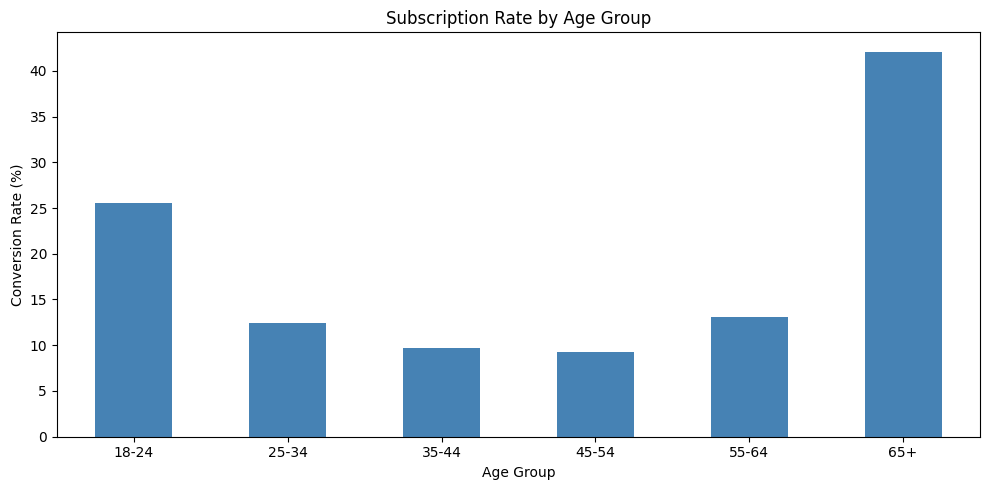

In [46]:

age_summary["conversion_rate"].plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
print(
    age_summary[
        ["total_customers", "subscriptions", "conversion_rate"]
    ].round(2)
)

           total_customers  subscriptions  conversion_rate
age_group                                                 
18-24                  809            207            25.59
25-34                14204           1773            12.48
35-44                14534           1404             9.66
45-54                 9958            923             9.27
55-64                 4896            641            13.09
65+                    810            341            42.10


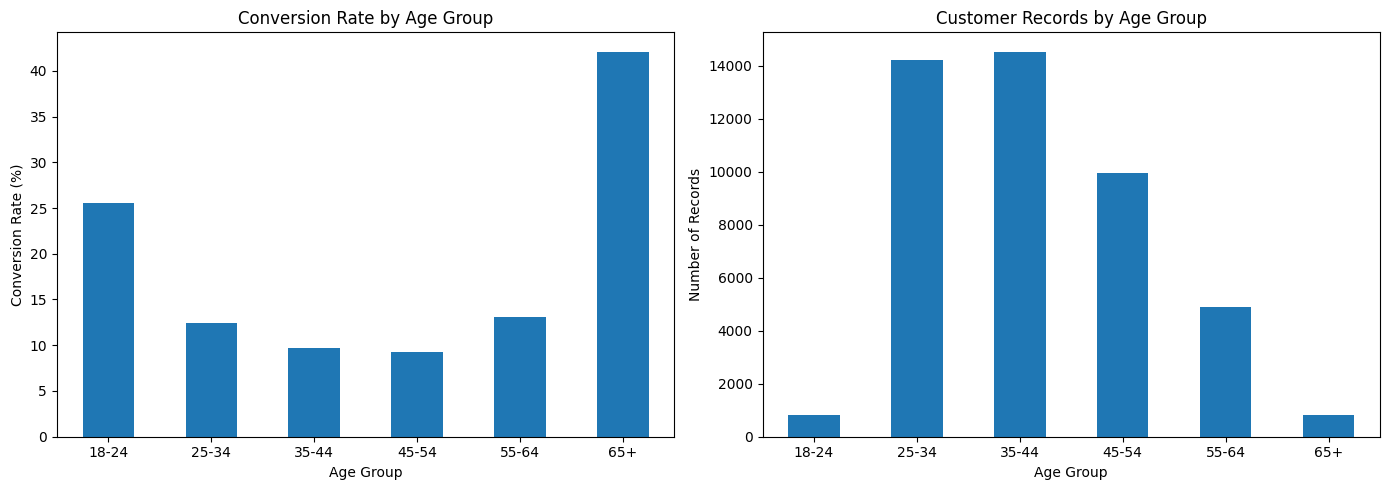

In [48]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

age_summary["conversion_rate"].plot(
    kind="bar",
    ax=axes[0],
    title="Conversion Rate by Age Group"
)

age_summary["total_customers"].plot(
    kind="bar",
    ax=axes[1],
    title="Customer Records by Age Group"
)

axes[0].set_ylabel("Conversion Rate (%)")
axes[1].set_ylabel("Number of Records")

for ax in axes:
    ax.set_xlabel("Age Group")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [49]:

pivot_table = df.pivot_table(
    index="job",
    columns="age_group",
    values="y",
    aggfunc=lambda x: (x == "yes").mean() * 100,
    observed=True
)

pivot_table.round(2)

age_group,18-24,25-34,35-44,45-54,55-64,65+
job,,,,,,
admin.,15.56,13.08,9.93,12.16,16.54,33.33
blue-collar,14.29,8.66,6.34,6.50,7.31,0.00
entrepreneur,40.00,7.33,8.62,8.17,6.79,50.00
housemaid,33.33,6.91,6.25,8.35,9.82,40.00
management,35.90,15.49,12.35,11.46,16.11,33.33
retired,0.00,14.29,3.39,8.16,15.81,43.56
self-employed,45.45,17.04,9.53,5.68,13.48,62.50
services,18.60,9.68,8.82,7.05,7.58,0.00
student,35.78,24.59,25.86,50.00,NaN,NaN


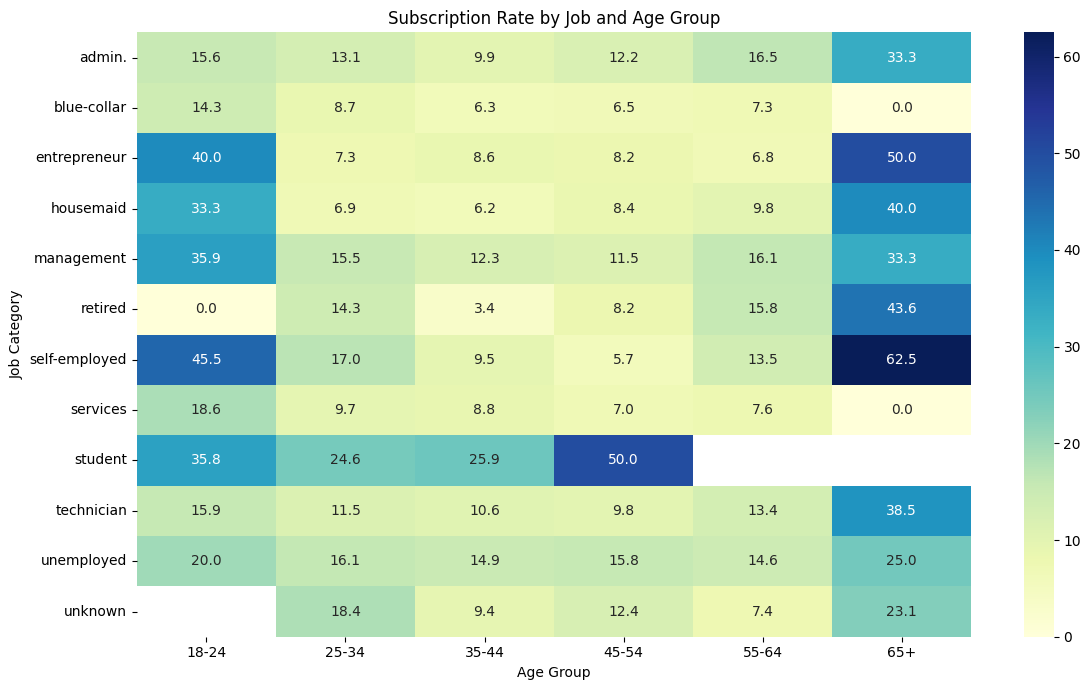

In [50]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Subscription Rate by Job and Age Group")
plt.xlabel("Age Group")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

In [51]:
segment_counts = df.pivot_table(
    index="job",
    columns="age_group",
    values="y",
    aggfunc="count",
    observed=True
)

segment_counts.fillna(0).astype(int)

age_group,18-24,25-34,35-44,45-54,55-64,65+
job,,,,,,
admin.,90,1842,1691,1143,393,12
blue-collar,147,2967,3486,2401,725,6
entrepreneur,5,341,557,416,162,6
housemaid,6,188,336,395,285,30
management,39,3131,3264,2051,931,42
retired,1,7,59,282,1240,675
self-employed,11,493,556,370,141,8
services,86,1529,1394,880,264,1
student,327,549,58,4,0,0


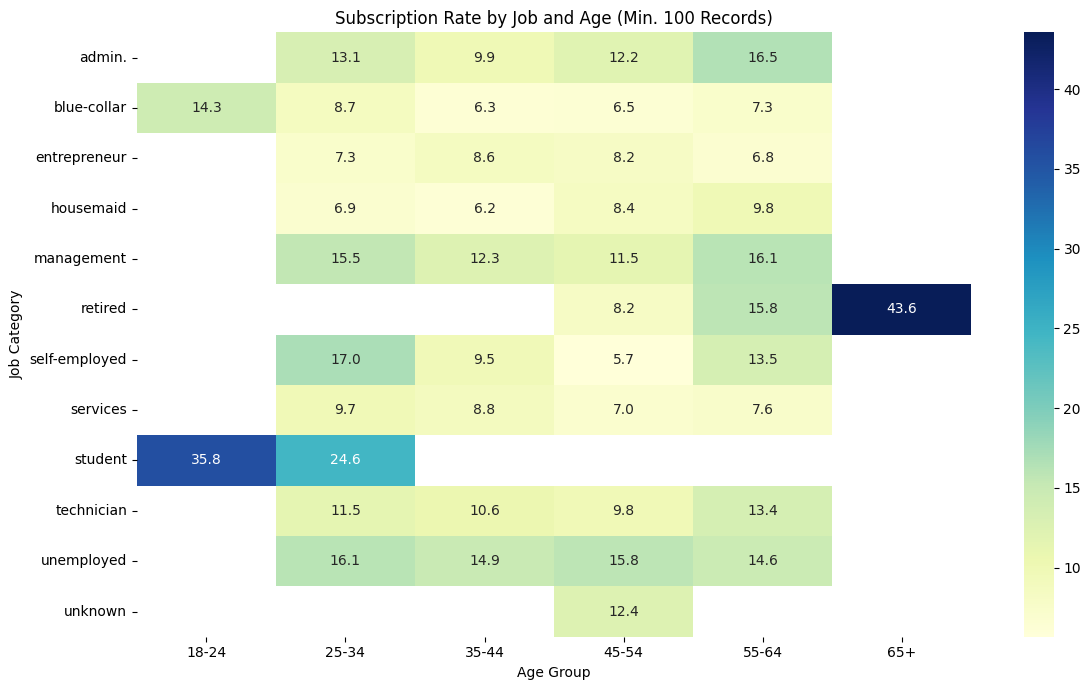

In [52]:

reliable_segments = pivot_table.where(
    segment_counts >= 100
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    reliable_segments,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Subscription Rate by Job and Age (Min. 100 Records)")
plt.xlabel("Age Group")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

In [53]:

df["campaign"].describe()

,campaign
count,45211.000000
mean,2.763841
std,3.098021
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,63.000000


In [54]:

df["campaign"].value_counts().sort_index().head(15)

,count
campaign,
1,17544
2,12505
3,5521
4,3522
5,1764
6,1291
7,735
8,540
9,327


In [55]:

df["contact_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)

contact_summary = df.groupby(
    "contact_group", observed=True
)["y"].agg(
    total_records="count",
    subscriptions=lambda x: (x == "yes").sum()
)

contact_summary["conversion_rate"] = (
    contact_summary["subscriptions"] /
    contact_summary["total_records"] * 100
)

contact_summary.round(2)

,total_records,subscriptions,conversion_rate
contact_group,,,
1,17544,2561,14.60
2,12505,1401,11.20
3,5521,618,11.19
4-5,5286,456,8.63
6-10,3159,206,6.52
11+,1196,47,3.93


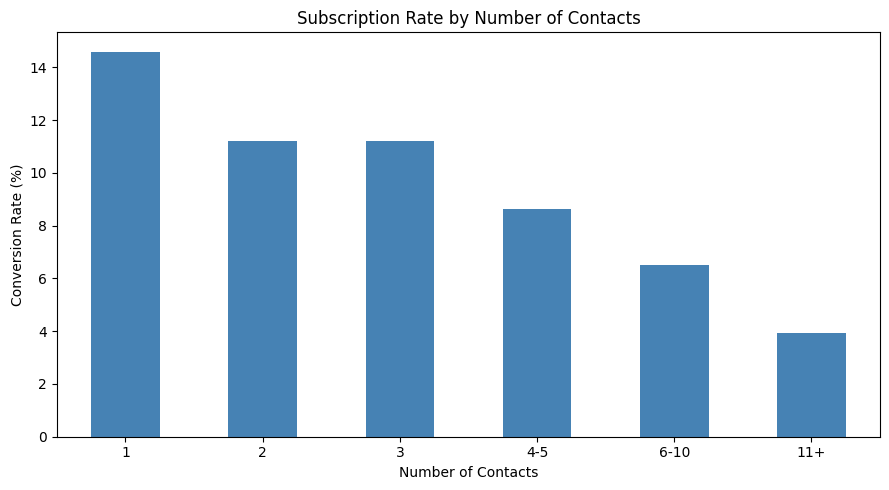

In [56]:

contact_summary["conversion_rate"].plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Subscription Rate by Number of Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:

df["poutcome"].value_counts()

,count
poutcome,
unknown,36959
failure,4901
other,1840
success,1511


In [58]:

previous_summary = df.groupby("poutcome")["y"].agg(
    total_records="count",
    subscriptions=lambda x: (x == "yes").sum()
)

previous_summary["conversion_rate"] = (
    previous_summary["subscriptions"] /
    previous_summary["total_records"] * 100
)

previous_summary.round(2)

,total_records,subscriptions,conversion_rate
poutcome,,,
failure,4901,618,12.61
other,1840,307,16.68
success,1511,978,64.73
unknown,36959,3386,9.16


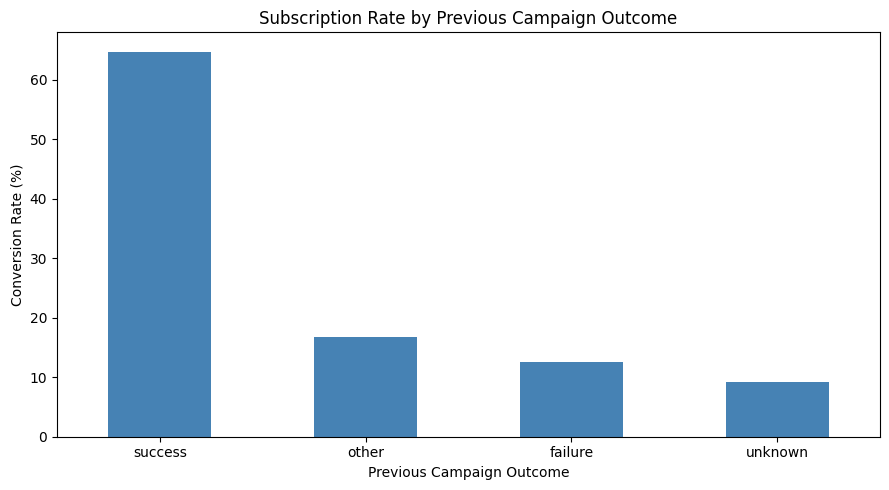

In [59]:
previous_summary["conversion_rate"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()